# Random Forest Validation Baseline

A Random Forest averages decision trees trained on bootstrap samples and feature subsets, allowing nonlinear relationships without feature scaling. This is an untuned Phase 8 baseline, not final model selection. It uses the schema-ordered 42 features, fits only on TRAIN, and evaluates only on VALIDATION. Random state is fixed at 42; other estimator settings use installed scikit-learn defaults.

The test split is not loaded or evaluated. No tuning, feature selection, model persistence, or SHAP analysis is performed.

In [2]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidate_roots if (p / 'ml/src/train_random_forest.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate ml/src/train_random_forest.py')
sys.path.insert(0, str(PROJECT_ROOT))
from ml.src.train_random_forest import run_phase8
report, artifacts = run_phase8()
train_rows = report['train_rows']
validation_rows = report['validation_rows']
feature_count = report['feature_count']
random_forest_parameters = report['resolved_random_forest_parameters']
print('Train rows / validation rows / features:', train_rows, validation_rows, feature_count)
print('Target:', report['target'])
print('Resolved RandomForestRegressor parameters:')
print(random_forest_parameters)
print('No scaler was fitted. Test set was not loaded or evaluated.')

Train rows / validation rows / features: 13108 2809 42
Target: target_appliances_next
Resolved RandomForestRegressor parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
No scaler was fitted. Test set was not loaded or evaluated.


## Validation Comparison

Phase 7 persistence and Linear Regression metrics are read from the existing validation-results JSON. Random Forest metrics are computed on VALIDATION only. RMSE is the primary comparison measure; this comparison does not select the final thesis model.

,MAE,RMSE,R²
Persistence Baseline,25.920256,65.794972,0.465273
Linear Regression,27.025294,59.346237,0.564956
Random Forest,53.004521,100.818362,-0.255527


Current best validation model by RMSE: Linear Regression
RF RMSE improvement vs persistence (%): -53.23110478593699
RF RMSE improvement vs Linear Regression (%): -69.881641150079
Actual vs Predicted period: first 7 contiguous validation days, 2016-04-18 17:40:00 through 2016-04-25 17:30:00 (1008 observations)


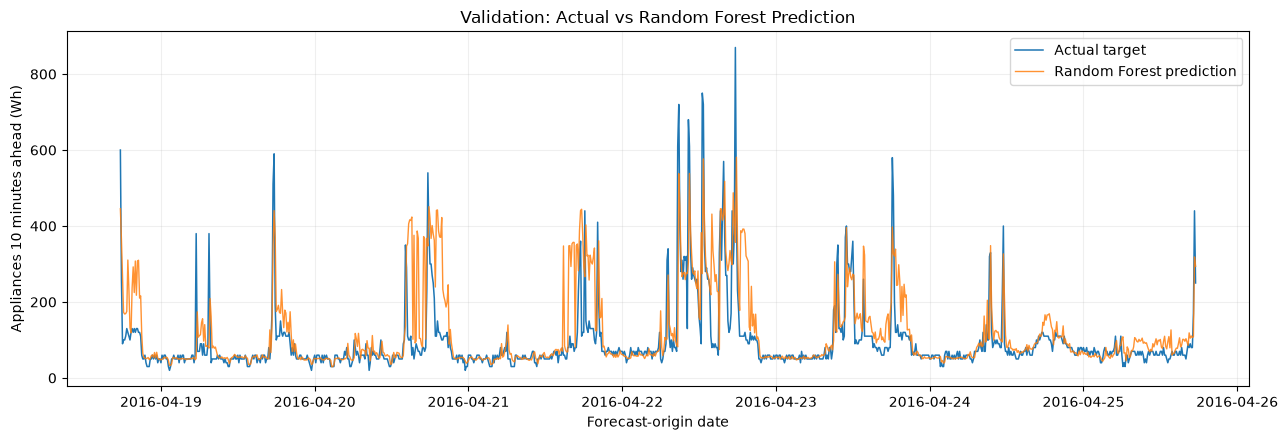

In [3]:
comparison = pd.DataFrame.from_dict(report['validation_model_comparison'], orient='index')
comparison = comparison.rename(columns={'mae': 'MAE', 'rmse': 'RMSE', 'r2': 'R²'})
display(comparison)
print('Current best validation model by RMSE:', report['current_best_validation_model_by_rmse'])
print('RF RMSE improvement vs persistence (%):', report['random_forest_improvement_vs_persistence_percent'])
print('RF RMSE improvement vs Linear Regression (%):', report['random_forest_improvement_vs_linear_regression_percent'])
validation_dates = artifacts['validation_dates']
window_mask = validation_dates < validation_dates.iloc[0] + pd.Timedelta(days=7)
window_dates = validation_dates.loc[window_mask]
actual_window = artifacts['actual'].loc[window_mask]
prediction_window = artifacts['predictions'].loc[window_mask]
print(f'Actual vs Predicted period: first 7 contiguous validation days, {window_dates.iloc[0]} through {window_dates.iloc[-1]} ({len(window_dates)} observations)')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(window_dates, actual_window, label='Actual target', linewidth=1.1)
ax.plot(window_dates, prediction_window, label='Random Forest prediction', linewidth=1.0, alpha=0.85)
ax.set(title='Validation: Actual vs Random Forest Prediction', xlabel='Forecast-origin date', ylabel='Appliances 10 minutes ahead (Wh)')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Residuals and Limitations

Residuals are actual validation target minus Random Forest prediction. These are validation diagnostics only; no residual-based row removal or parameter changes are made. The model is untuned, one chronological period is evaluated, and no causal interpretation is made.

Random Forest validation residual summary (actual - predicted):


count    2809.000000
mean      -34.858135
std        94.617332
min      -378.300000
25%       -38.200000
50%        -9.900000
75%         1.800000
max       572.500000
dtype: float64

Mean residual: -34.85813456746173


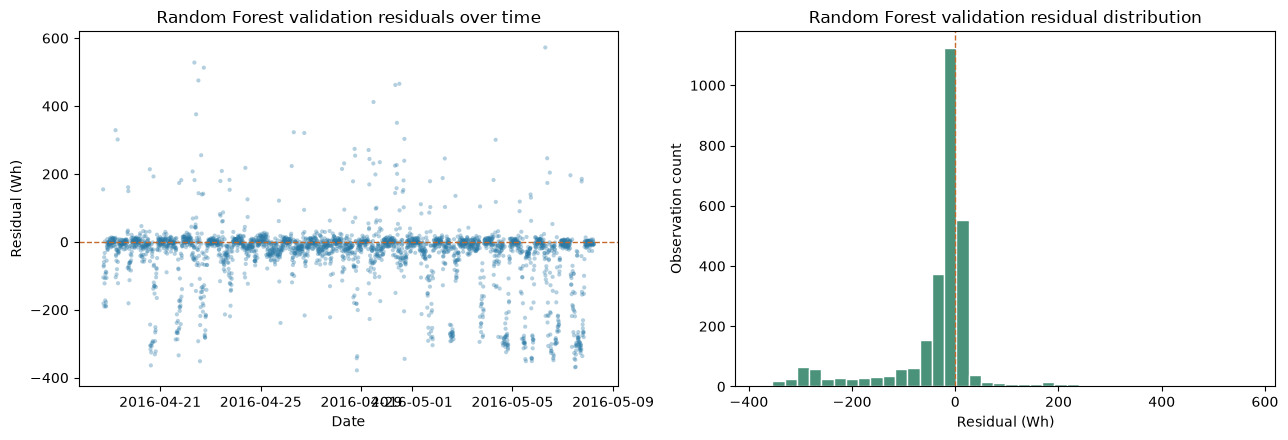

In [4]:
residuals = artifacts['residuals']
print('Random Forest validation residual summary (actual - predicted):')
display(residuals.describe())
print('Mean residual:', float(residuals.mean()))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(validation_dates, residuals, s=9, alpha=0.35, color='#2878A5', edgecolors='none')
axes[0].axhline(0, color='#C46A2D', linestyle='--', linewidth=1)
axes[0].set(title='Random Forest validation residuals over time', xlabel='Date', ylabel='Residual (Wh)')
axes[1].hist(residuals, bins=40, color='#4B927A', edgecolor='white')
axes[1].axvline(0, color='#C46A2D', linestyle='--', linewidth=1)
axes[1].set(title='Random Forest validation residual distribution', xlabel='Residual (Wh)', ylabel='Observation count')
fig.tight_layout()
plt.show()
assert report['test_set_accessed'] is False
assert report['scaling_applied'] is False and report['hyperparameter_tuning_performed'] is False
assert report['model_artifact_saved'] is False